# Description

Robustness check from #905: do the step 2 results hold if the model is
trained on a different target?

In step 2 the logistic regression is trained on the sign of the move. It is
right 52% of the time from 5m to 4h, but the moves it gets wrong are bigger,
so it makes almost nothing. Maybe it would do better if it were trained on
something closer to the PnL. Same features, same walk forward, same trades
as `tradability.models.ipynb`, with four targets (`D20`):
- `sign`: the sign of the move (step 2)
- `weighted_sign`: the sign, with each bar weighted by |r|, so that the
  model cares about the big moves
- `large_moves`: the sign, trained only on moves bigger than the 10 bp cost
- `return`: the return itself, with a ridge regression; trade its sign

For each one: hit rate and weighted hit rate, PnL per trade, which horizon
looks best, and whether it makes money after costs.

## Imports

In [1]:
%load_ext autoreload
%autoreload 2

import data_utils as dutil
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import predict_utils as putil

## Config

In [2]:
SYMBOLS = ["BTCUSDT", "ETHUSDT"]
INTERVAL = "5m"
START = "2020-01-01"
END = "2026-10-01"
HORIZONS = ["5m", "15m", "1h", "4h", "1d"]
# Fit on the years before each of these and test on it.
TEST_YEARS = [2022, 2023, 2024, 2025, 2026]
# Cost of a round trip: 10 bp, as in the plan on #733.
COST = 0.001
# Costs to sweep, from free trading to an expensive 20 bp.
COSTS = [0.0, 0.0002, 0.0005, 0.001, 0.002]
TARGETS = putil.TARGETS
# Train `large_moves` on the moves bigger than the cost.
MIN_MOVE = COST

## Data, features, labels

In [3]:
clean = {}
for symbol in SYMBOLS:
    raw = dutil.load_ohlcv(symbol, START, END, interval=INTERVAL)
    clean[symbol] = dutil.clean_bars(raw, interval=INTERVAL)
other = {"BTCUSDT": "ETHUSDT", "ETHUSDT": "BTCUSDT"}
features = {}
labels = {}
for symbol in SYMBOLS:
    features[symbol] = dutil.compute_features(
        clean[symbol],
        other=clean[other[symbol]],
        other_name=other[symbol][:3].lower(),
        interval=INTERVAL,
    )
    labels[symbol] = dutil.compute_labels(
        clean[symbol], HORIZONS, interval=INTERVAL
    )

## Predict and evaluate

One trade every horizon in 2022-01-01 to 2026-10-01, as in step 2. Besides
the metrics of `evaluate_positions()`:
- `se_bps`: standard error of the PnL per trade
- `t_stat`: PnL per trade / its standard error
- `share_long`: share of the trades that buy

In [4]:
test_start = f"{TEST_YEARS[0]}-01-01"
rows = []
trades = {}
for symbol in SYMBOLS:
    for horizon in HORIZONS:
        sample = dutil.sample_non_overlapping(
            labels[symbol], horizon, interval=INTERVAL
        )
        sample = sample[sample.index >= test_start]
        fwd_ret = sample[f"fwd_ret_{horizon}"]
        for target in TARGETS:
            pos = putil.predict_with_target(
                features[symbol],
                labels[symbol],
                horizon,
                TEST_YEARS,
                target=target,
                min_move=MIN_MOVE,
                interval=INTERVAL,
            )
            pos = pos.reindex(sample.index)
            trades[(symbol, horizon, target)] = pd.DataFrame(
                {"pos": pos, "fwd_ret": fwd_ret}
            )
            stats = putil.evaluate_positions(pos, fwd_ret, cost=COST)
            pnl = (pos * fwd_ret).dropna()
            pnl = pnl[fwd_ret.reindex(pnl.index) != 0]
            stats["se_bps"] = pnl.std() / np.sqrt(len(pnl)) * 1e4
            stats["t_stat"] = stats["gross_bps"] / stats["se_bps"]
            stats["share_long"] = (pos.dropna() > 0).mean()
            rows.append(
                {
                    "symbol": symbol,
                    "horizon": horizon,
                    "target": target,
                    **stats,
                }
            )
results = pd.DataFrame(rows).set_index(["symbol", "horizon", "target"])
columns = [
    "n",
    "hit_rate",
    "weighted_hit_rate",
    "gross_bps",
    "se_bps",
    "t_stat",
    "share_long",
]
results[columns].round(3)

n  hit_rate  weighted_hit_rate  \
symbol  horizon target                                                 
BTCUSDT 5m      sign           495975.0     0.518              0.501   
                weighted_sign  495975.0     0.510              0.502   
                large_moves    495975.0     0.517              0.502   
                return         495975.0     0.513              0.501   
        15m     sign           165692.0     0.521              0.506   
                weighted_sign  165692.0     0.508              0.503   
                large_moves    165692.0     0.521              0.507   
                return         165692.0     0.513              0.504   
        1h      sign            41432.0     0.523              0.503   
                weighted_sign   41432.0     0.509              0.503   
                large_moves     41432.0     0.522              0.502   
                return          41432.0     0.515              0.503   
        4h      sign            10359.0     0.526              0.512   
                weighted_sign   10359.0     0.506              0.509   
                large_moves     10359.0     0.528              0.513   
                return          10359.0     0.514              0.506   
        1d      sign             1724.0     0.501              0.513   
                weighted_sign    1724.0     0.500              0.507   
                large_moves      1724.0     0.502              0.513   
                return           1724.0     0.496              0.492   
ETHUSDT 5m      sign           495898.0     0.520              0.498   
                weighted_sign  495898.0     0.507              0.498   
                large_moves    495898.0     0.519              0.498   
                return         495898.0     0.509              0.498   
        15m     sign           165561.0     0.523              0.501   
                weighted_sign  165561.0     0.505              0.497   
                large_moves    165561.0     0.522              0.501   
                return         165561.0     0.507              0.498   
        1h      sign            41415.0     0.521              0.498   
                weighted_sign   41415.0     0.505              0.496   
                large_moves     41415.0     0.521              0.499   
                return          41415.0     0.512              0.500   
        4h      sign            10354.0     0.519              0.507   
                weighted_sign   10354.0     0.501              0.490   
                large_moves     10354.0     0.518              0.507   
                return          10354.0     0.506              0.494   
        1d      sign             1725.0     0.521              0.519   
                weighted_sign    1725.0     0.509              0.497   
                large_moves      1725.0     0.519              0.520   
                return           1725.0     0.508              0.506   

                               gross_bps  se_bps  t_stat  share_long  
symbol  horizon target                                                
BTCUSDT 5m      sign               0.022   0.023   0.969       0.478  
                weighted_sign      0.043   0.023   1.881       0.363  
                large_moves        0.031   0.023   1.382       0.530  
                return             0.016   0.023   0.697       0.402  
        15m     sign               0.202   0.068   2.993       0.526  
                weighted_sign      0.091   0.068   1.341       0.394  
                large_moves        0.228   0.068   3.371       0.533  
                return             0.149   0.068   2.208       0.392  
        1h      sign               0.210   0.266   0.790       0.597  
                weighted_sign      0.178   0.266   0.670       0.453  
                large_moves        0.116   0.266   0.437       0.612  
                return             0.226   0.266   0.850       0.384  
        4h      sig

## Hit rate and weighted hit rate per target

- Solid lines: hit rate
- Dashed lines: weighted hit rate, the share of the total |r| traded in the
  right direction. The PnL before costs is positive only above 0.5

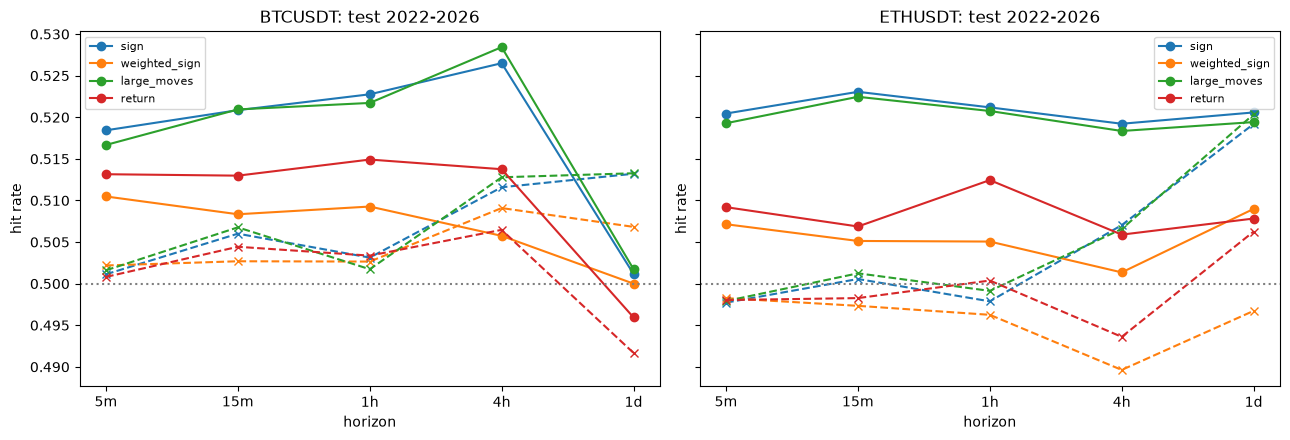

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, symbol in zip(axes, SYMBOLS):
    for i, target in enumerate(TARGETS):
        sub = results.loc[(symbol, slice(None), target)]
        color = f"C{i}"
        ax.plot(HORIZONS, sub["hit_rate"], marker="o", color=color, label=target)
        ax.plot(
            HORIZONS,
            sub["weighted_hit_rate"],
            marker="x",
            linestyle="--",
            color=color,
        )
    ax.axhline(0.5, color="gray", linestyle=":")
    ax.set_title(f"{symbol}: test 2022-2026")
    ax.set_xlabel("horizon")
    ax.set_ylabel("hit rate")
    ax.legend(fontsize=8)
plt.tight_layout()

## PnL per trade before costs

Average PnL per trade, with error bars of 2 standard errors. It is also the
break-even cost: the cost at which the target stops making money.

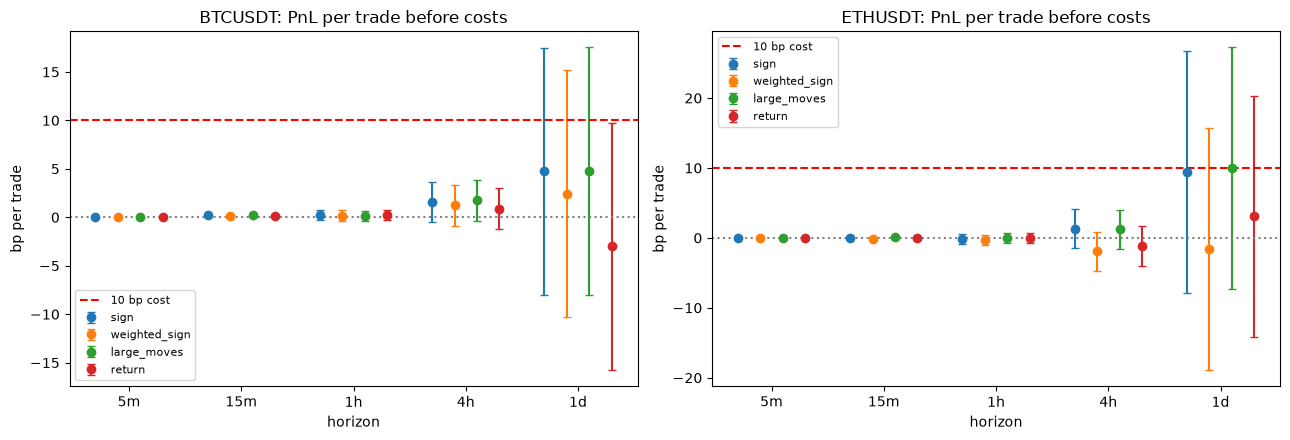

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
x = np.arange(len(HORIZONS))
width = 0.2
for ax, symbol in zip(axes, SYMBOLS):
    for i, target in enumerate(TARGETS):
        sub = results.loc[(symbol, slice(None), target)]
        ax.errorbar(
            x + (i - 1.5) * width,
            sub["gross_bps"],
            yerr=2 * sub["se_bps"],
            fmt="o",
            capsize=3,
            label=target,
        )
    ax.axhline(0, color="gray", linestyle=":")
    ax.axhline(COST * 1e4, color="red", linestyle="--", label="10 bp cost")
    ax.set_xticks(x, HORIZONS)
    ax.set_title(f"{symbol}: PnL per trade before costs")
    ax.set_xlabel("horizon")
    ax.set_ylabel("bp per trade")
    ax.legend(fontsize=8)
plt.tight_layout()

## Break-even cost per target and horizon

The cost at which each target stops making money, in bp per round trip: its
PnL per trade before costs, or 0 if it loses money even for free. A target
makes money at a cost only if its break-even cost is above it.

In [7]:
break_even = results["gross_bps"].clip(lower=0).unstack("horizon")[HORIZONS]
break_even = break_even.reindex(
    pd.MultiIndex.from_product([SYMBOLS, TARGETS]), axis=0
)
break_even.round(2)

horizon                  5m   15m    1h    4h    1d
BTCUSDT sign           0.02  0.20  0.21  1.58  4.75
        weighted_sign  0.04  0.09  0.18  1.24  2.45
        large_moves    0.03  0.23  0.12  1.75  4.77
        return         0.02  0.15  0.23  0.88  0.00
ETHUSDT sign           0.00  0.02  0.00  1.30  9.39
        weighted_sign  0.00  0.00  0.00  0.00  0.00
        large_moves    0.00  0.06  0.00  1.21  9.96
        return         0.00  0.00  0.03  0.00  3.06

PnL per trade after costs (bp) of each target at its best horizon, for each
cost.

In [8]:
rows = []
for (symbol, horizon, target), df in trades.items():
    sweep = putil.sweep_costs(df["pos"], df["fwd_ret"], COSTS)
    sweep["symbol"] = symbol
    sweep["horizon"] = horizon
    sweep["target"] = target
    rows.append(sweep)
sweep = pd.concat(rows, ignore_index=True)
# The best horizon is the one with the highest break-even cost.
best_horizon = results["gross_bps"].groupby(["symbol", "target"]).idxmax()
best_horizon = best_horizon.map(lambda key: key[1])
mask = [
    best_horizon[(symbol, target)] == horizon
    for symbol, horizon, target in zip(
        sweep["symbol"], sweep["horizon"], sweep["target"]
    )
]
best = sweep[mask].pivot_table(
    index=["symbol", "target", "horizon"], columns="cost_bps", values="net_bps"
)
best.round(2)

cost_bps                       0.0   2.0   5.0    10.0   20.0
symbol  target        horizon                                
BTCUSDT large_moves   1d       4.77  2.77 -0.23  -5.23 -15.23
        return        4h       0.88 -1.12 -4.12  -9.12 -19.12
        sign          1d       4.75  2.75 -0.25  -5.25 -15.25
        weighted_sign 1d       2.45  0.45 -2.55  -7.55 -17.55
ETHUSDT large_moves   1d       9.96  7.96  4.96  -0.04 -10.04
        return        1d       3.06  1.06 -1.94  -6.94 -16.94
        sign          1d       9.39  7.39  4.39  -0.61 -10.61
        weighted_sign 5m      -0.04 -2.04 -5.04 -10.04 -20.04

## Observations

- No target fixes the step 2 problem. From 5m to 1h the weighted hit rate
  stays at 0.50 +/- 0.01 for every target, and before costs none makes more
  than 0.23 bp per trade. Changing the target does not make the model right
  more often on the big moves
- `large_moves` gives almost the same results as `sign`: hit rate within
  0.3 points, PnL per trade within 0.2 bp from 5m to 4h. Most of what the
  model learns comes from the moves bigger than 10 bp anyway
- `weighted_sign` and `return` are not better. Their hit rate drops to
  50-51.5%. From 5m to 1h all four targets are within the noise; at 4h and
  1d these two make less than `sign` on both coins. Probably because a few
  very big moves dominate their fit
- These two targets also buy less often (36-58% of the trades from 5m to 4h,
  vs 46-68% for `sign`), so they get less of the 2020-2026 uptrend
- The best horizon does not change: it is 1d for every target, except
  `return` on BTC (4h, 0.9 bp before costs) and `weighted_sign` on ETH,
  which loses money at every horizon. At 10 bp no target makes money.
  The closest is `large_moves` on ETH at 1d, which breaks even at 10.0 bp,
  but on 1,725 trades with a standard error of 8.6 bp
- So the step 2 conclusion holds with all four targets: it does not depend
  on training on the sign of the move